# Trabajo Práctico N° 3: SVM y Random Forest

- Año: 2026
- Materia: Minería de Datos
- Integrantes: Frank, Maximiliano; Winter, Federico

Recomendamos uno de 10 cultivos a partir de 16 variables de suelo y clima. El conjunto parte de un dataset de Kaggle ([fuente](https://www.kaggle.com/datasets/markjehan/global-crop-recommendation)), modificado para este trabajo según el enunciado. Todas las particiones, validaciones cruzadas y modelos usan random_state=13.

In [3]:
# Importo las librerías y fijo la semilla
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

SEED = 13  # random_state de todas las particiones, validaciones cruzadas y modelos


# Defino una función que agrega "Figura n" debajo del gráfico
def numerar(n):
    plt.tight_layout(rect=(0, 0.04, 1, 1))
    plt.figtext(0.5, 0.01, f"Figura {n}", ha="center", va="bottom")


## 1. Preparación de datos

El archivo crop_recommendation_geo.csv tiene 50004 filas y 17 columnas (50005 líneas con el encabezado). Usamos los nombres de columna del CSV.

| Variable | Qué representa | Tipo | Rol |
|---|---|---|---|
| N | Nitrógeno total en el suelo (0-30 cm) | Numérica continua | Predictora |
| P | Fósforo disponible para las plantas (Olsen) | Numérica continua | Predictora |
| exch_bases | Bases intercambiables totales (Ca + Mg + K + Na) de la capa superficial del suelo | Numérica continua | Predictora |
| ph | pH del suelo en agua (0-30 cm) | Numérica continua | Predictora |
| soc | Carbono orgánico del suelo (0-30 cm) | Numérica continua | Predictora |
| arcilla | Fracción arcillosa (0-30 cm) | Numérica continua | Predictora |
| arena | Fracción de arena (0-30 cm) | Numérica continua | Predictora |
| cec | Capacidad de intercambio catiónico | Numérica continua | Predictora |
| temperatura | Temperatura media anual del aire | Numérica continua | Predictora |
| temp_min_mensual | Temperatura media del mes más frío | Numérica continua | Predictora |
| temp_max_mensual | Temperatura media del mes más cálido | Numérica continua | Predictora |
| humedad | Humedad relativa media anual | Numérica continua | Predictora |
| lluvia | Precipitación anual | Numérica discreta | Predictora |
| estacionalidad_lluvias | Coeficiente de variación de la precipitación mensual (BIO15) | Numérica continua | Predictora |
| radiacion_solar | Radiación solar incidente media anual | Numérica continua | Predictora |
| elevacion | Altura sobre el nivel del mar | Numérica discreta | Predictora |
| clase | Cultivo recomendado (algodon, arroz, banana, cafe, coco, frijol, garbanzo, lenteja, maiz y manzana) | Categórica nominal | Objetivo |

Hipótesis: las tres variables de temperatura están muy correlacionadas entre sí, P, soc, lluvia y elevacion tienen una cola larga a la derecha, y como el conjunto se modificó a propósito esperamos nulos, duplicados y valores fuera de rango.

### 1.1 Carga y tipos de datos

In [4]:
# Leo el CSV con ";" como separador y "," como decimal
df = pd.read_csv("crop_recommendation_geo.csv", sep=";", decimal=",")
display(df.head())
df.info()


,N,P,exch_bases,ph,soc,arcilla,arena,cec,temperatura,temp_min_mensual,temp_max_mensual,humedad,lluvia,estacionalidad_lluvias,radiacion_solar,elevacion,clase
0,1.353,6.689,13.5,7.233,11.167,24.867,31.017,16.867,24.868,15.185,31.804,65.161,1148,126.689,19.228,96,arroz
1,1.855,11.072,16.9,6.083,15.583,37.217,25.750,15.933,23.829,16.888,29.372,83.058,1740,81.048,15.206,3,arroz
2,1.727,14.273,29.0,6.400,15.717,26.667,35.000,23.683,18.029,7.566,27.969,77.170,1108,65.502,11.994,316,arroz
3,1.442,7.527,3.0,6.283,18.067,36.700,27.300,19.083,18.042,6.620,28.075,78.908,1483,51.357,13.621,343,arroz
4,1.920,12.067,15.8,6.983,16.600,28.733,29.450,18.533,16.284,7.726,24.241,59.990,471,83.554,16.836,6,arroz


<class 'pandas.DataFrame'>
RangeIndex: 50004 entries, 0 to 50003
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   N                       50004 non-null  float64
 1   P                       50004 non-null  float64
 2   exch_bases              50004 non-null  float64
 3   ph                      50003 non-null  float64
 4   soc                     50004 non-null  float64
 5   arcilla                 50004 non-null  float64
 6   arena                   50004 non-null  float64
 7   cec                     50003 non-null  float64
 8   temperatura             50004 non-null  float64
 9   temp_min_mensual        50004 non-null  float64
 10  temp_max_mensual        50004 non-null  float64
 11  humedad                 50003 non-null  float64
 12  lluvia                  50004 non-null  int64  
 13  estacionalidad_lluvias  50004 non-null  float64
 14  radiacion_solar         50004 non-null  float64
 

El conjunto tiene 16 predictoras numéricas (14 continuas y 2 enteras: lluvia y elevacion) y clase como texto. ph, cec y humedad tienen un nulo cada una.

### 1.2 Resumen estadístico y asimetría

In [5]:
# Reviso nulos, duplicados, descriptivas y asimetría de las variables predictoras
num_cols = df.columns.drop("clase")
print("Columnas con nulos:", df.isna().any().sum())
print("Valores nulos por columna:")
print(df.isna().sum()[df.isna().sum() > 0].to_string())
print("Filas duplicadas:", df.duplicated().sum())
print("\nAsimetría de cada variable:")
print(df[num_cols].skew().round(2).to_string())
df.describe().T.round(2)


Columnas con nulos: 3
Valores nulos por columna:
ph         1
cec        1
humedad    1
Filas duplicadas: 198

Asimetría de cada variable:
N                         1.78
P                         3.90
exch_bases                0.84
ph                        0.13
soc                       4.74
arcilla                   0.16
arena                     0.54
cec                       0.95
temperatura              -0.79
temp_min_mensual         -0.85
temp_max_mensual         -0.29
humedad                  -0.32
lluvia                    1.25
estacionalidad_lluvias    0.43
radiacion_solar          -0.22
elevacion                 2.41


,count,mean,std,min,25%,50%,75%,max
N,50004.0,1.81,0.96,0.26,1.10,1.63,2.27,15.10
P,50004.0,10.31,11.11,0.00,3.68,6.67,12.89,180.00
exch_bases,50004.0,17.86,11.98,0.10,7.00,16.00,26.50,143.00
ph,50003.0,6.48,1.02,4.05,5.55,6.50,7.35,25.32
soc,50004.0,24.34,26.46,1.02,11.02,18.12,27.18,322.82
arcilla,50004.0,31.24,8.05,2.40,25.63,31.03,36.77,142.38
arena,50004.0,36.90,13.56,0.88,28.02,34.68,45.03,94.50
cec,50003.0,20.46,7.74,3.72,15.55,19.55,24.23,70.82
temperatura,50004.0,19.24,7.72,-7.38,14.22,21.96,25.79,44.63
temp_min_mensual,50004.0,11.91,12.63,-27.87,3.10,16.44,22.10,27.92


Hay 3 valores nulos y 198 filas duplicadas. Tres variables pasan su rango físico: ph llega a 25.3, cuando el pH no pasa de 14, y humedad y arcilla, que son porcentajes, pasan de 100. Como esperábamos, hay nulos, duplicados y valores fuera de rango.

La asimetría confirma la parte de la hipótesis sobre las colas: soc (4.74), P (3.90), elevacion (2.41), N (1.78) y lluvia (1.25) tienen cola derecha.

### 1.3 Distribución de las variables predictoras

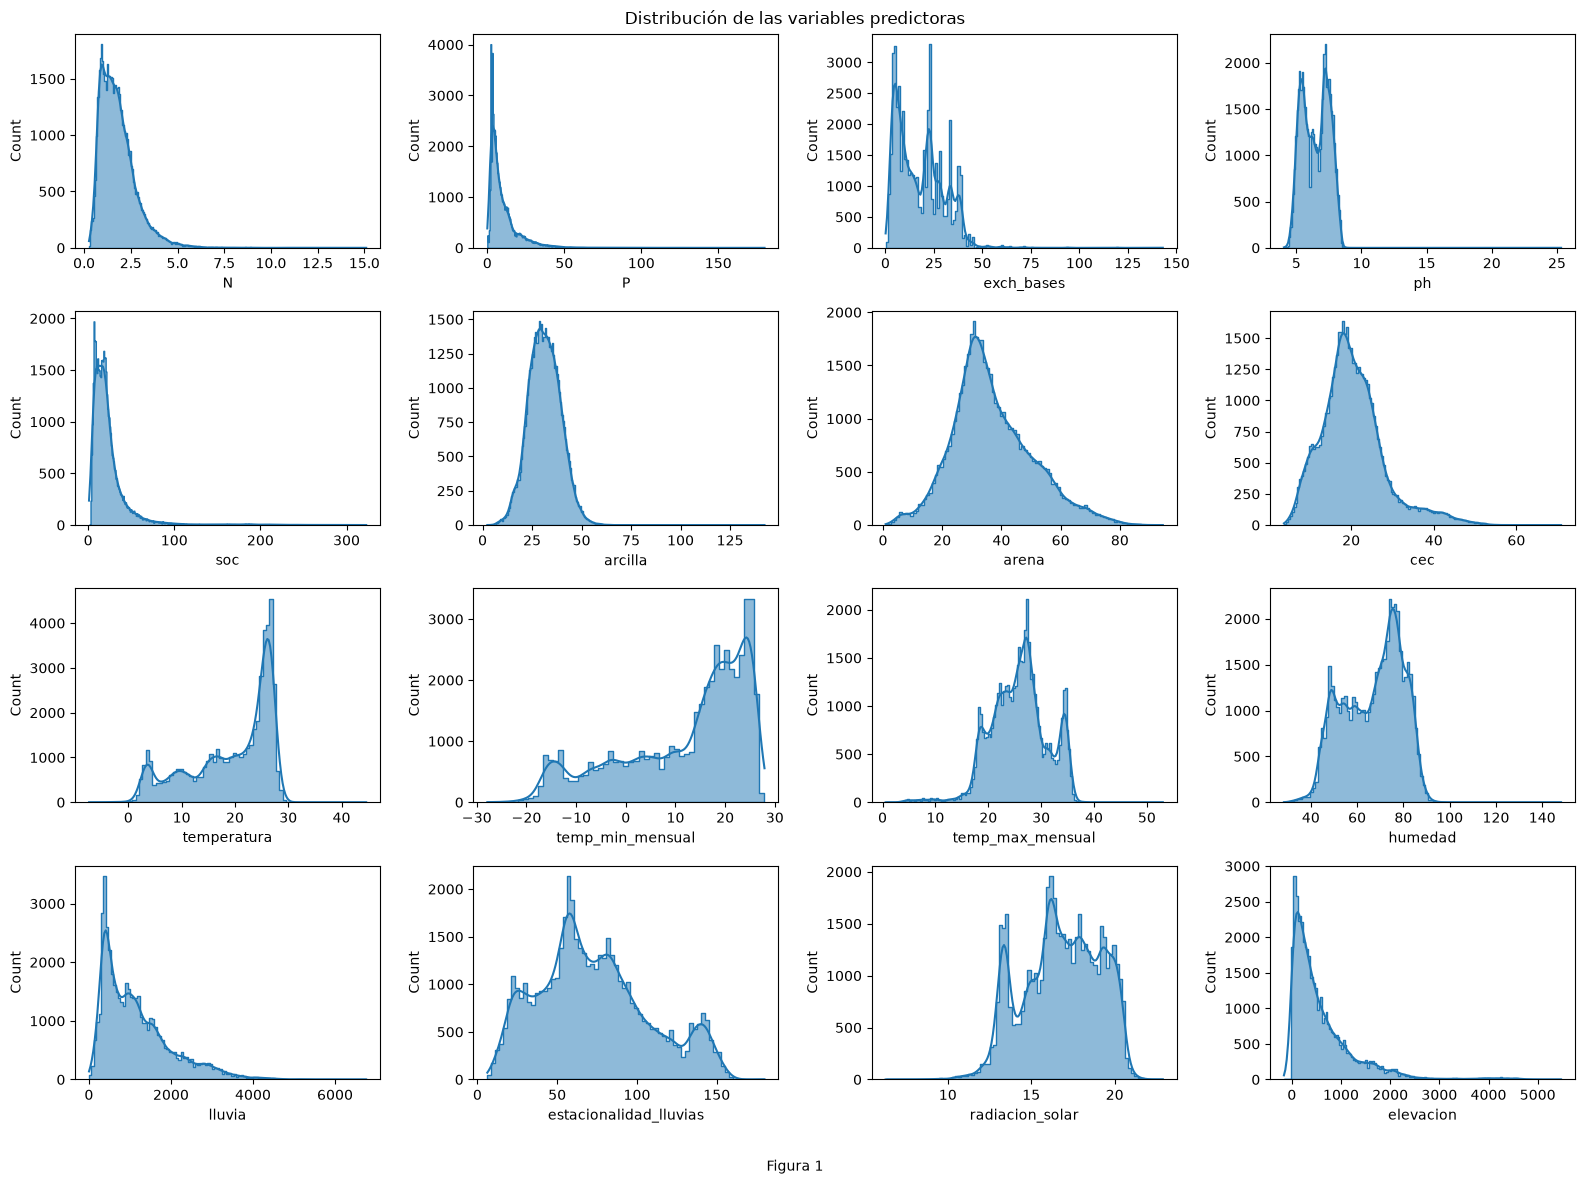

In [6]:
# Grafico la distribución de cada variable predictora
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for i, col in enumerate(num_cols):
    sns.histplot(data=df, x=col, kde=True, element="step", ax=axes.flatten()[i])
plt.suptitle("Distribución de las variables predictoras")
numerar(1)
plt.show()


Figura 1. N, P, soc, lluvia y elevacion se concentran cerca de cero con una cola larga a la derecha: P tiene mediana 6.67 y máximo 180. temperatura y temp_min_mensual tienen la cola hacia valores bajos. ph tiene dos picos, cerca de 5.4 y 7.5, y su eje llega hasta 25 por dos valores aislados. exch_bases y radiacion_solar también tienen varios picos. Los picos múltiples sugieren que cada cultivo ocupa un rango distinto de esas variables. Coincide con la hipótesis: P, soc, lluvia y elevacion tienen cola larga a la derecha.

### 1.4 Distribución de la variable objetivo

Hipótesis: esperamos un leve desbalance entre clases, como menciona el enunciado.

,Cantidad,Porcentaje
clase,,
cafe,5002,10.0
arroz,5001,10.0
manzana,5001,10.0
maiz,5000,10.0
garbanzo,5000,10.0
algodon,5000,10.0
banana,5000,10.0
frijol,5000,10.0
coco,5000,10.0


Razón clase mayoritaria / minoritaria: 1.0


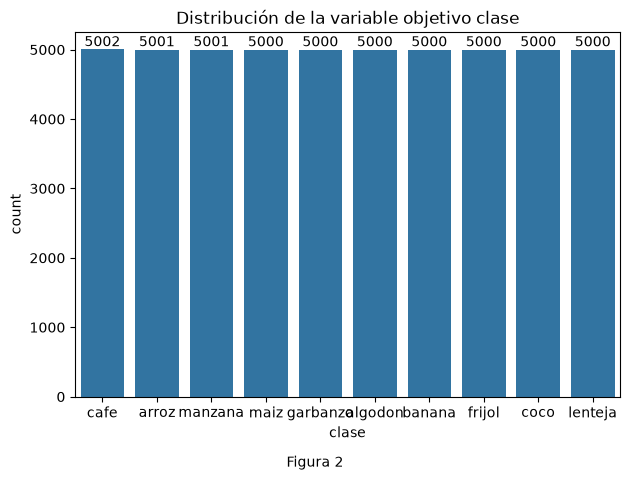

In [7]:
# Miro el balance de la variable objetivo clase
cantidad = df["clase"].value_counts()
balance = pd.DataFrame({"Cantidad": cantidad, "Porcentaje": (cantidad / len(df) * 100).round(2)})
display(balance)
print("Razón clase mayoritaria / minoritaria:", round(cantidad.max() / cantidad.min(), 3))

ax = sns.countplot(data=df, x="clase", order=cantidad.index)
ax.bar_label(ax.containers[0])
plt.title("Distribución de la variable objetivo clase")
numerar(2)
plt.show()


Figura 2. Las 10 clases tienen cerca de 5000 filas cada una, con razón de 1.0 entre la mayor y la menor. La hipótesis no se cumple en el archivo original: el leve desbalance aparece recién al eliminar los duplicados.

### 1.5 Correlaciones

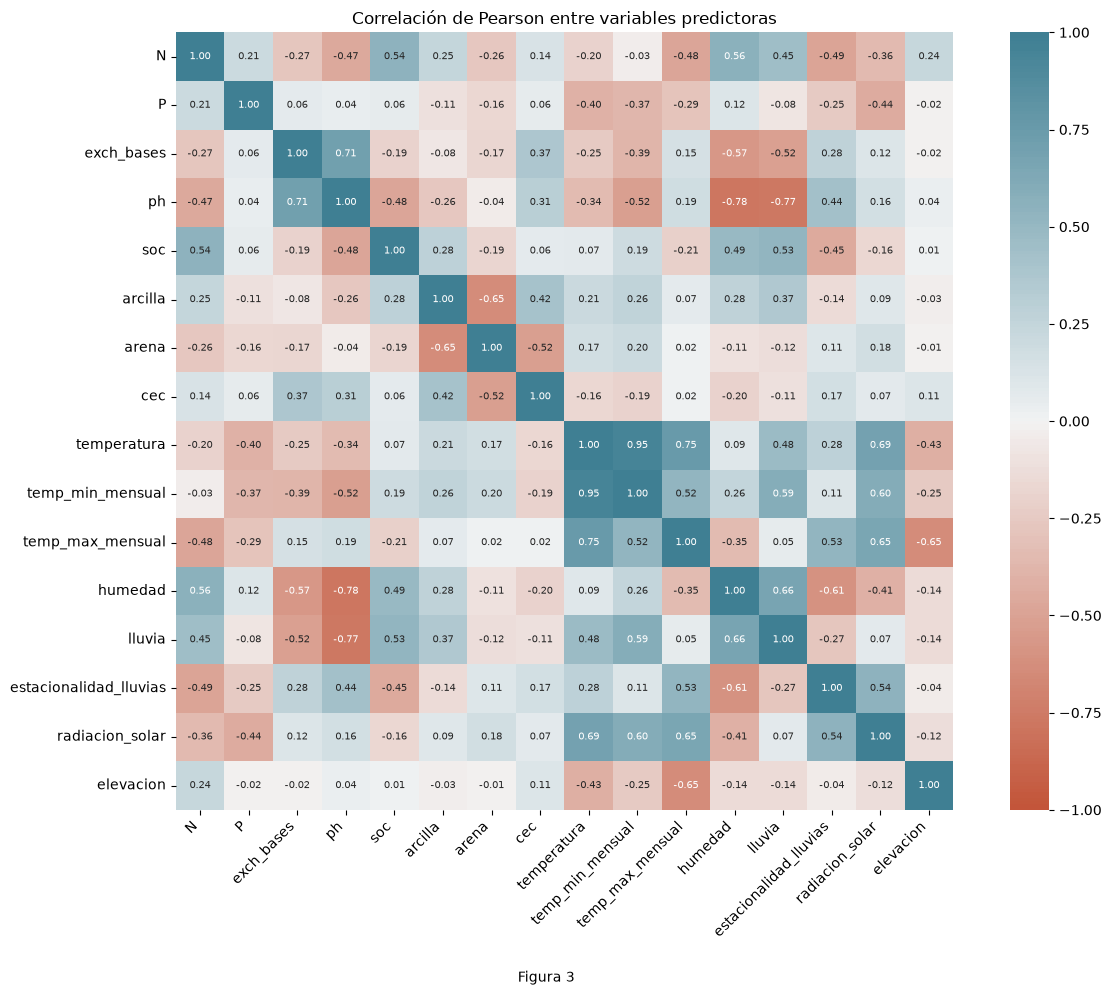

In [8]:
# Grafico la matriz de correlación de Pearson entre las variables predictoras
corr = df[num_cols].corr(method="pearson")
plt.figure(figsize=(13, 10))
ax = sns.heatmap(corr, vmin=-1, vmax=1, center=0,
                 cmap=sns.diverging_palette(20, 220, n=200),
                 square=True, annot=True, fmt=".2f", annot_kws={"size": 7})
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, horizontalalignment="right")
plt.title("Correlación de Pearson entre variables predictoras")
numerar(3)
plt.show()


Figura 3. temperatura se relaciona con temp_min_mensual (0.95) y con temp_max_mensual (0.75), pero temp_min_mensual y temp_max_mensual solo llegan a 0.52 entre sí, así que la hipótesis se cumple en parte. ph tiene correlación alta con humedad (-0.78), con lluvia (-0.77) y con exch_bases (0.71).

No eliminamos variables correlacionadas, porque la consigna no pide selección de variables. En el Random Forest la importancia se reparte entre ellas.

### 1.6 (a) Valores faltantes

In [9]:
# (a) Valores faltantes: muestro la fila que los contiene
display(df[df.isna().any(axis=1)])


,N,P,exch_bases,ph,soc,arcilla,arena,cec,temperatura,temp_min_mensual,temp_max_mensual,humedad,lluvia,estacionalidad_lluvias,radiacion_solar,elevacion,clase
25085,2.773,3.891,3.8,NaN,33.017,31.333,48.217,NaN,19.355,15.852,22.09,NaN,1294,63.371,14.632,769,cafe


Los 3 nulos están en una sola fila, de clase cafe. La eliminamos: es 1 de 50004 filas, e imputarla reemplazaría 3 de sus 16 valores por constantes que no salen de ninguna medición.

### 1.7 (b) Registros duplicados

In [10]:
# (b) Registros duplicados: cuento cuántos hay por clase
print("Filas duplicadas:", df.duplicated().sum())
print(df[df.duplicated()]["clase"].value_counts().to_string())


Filas duplicadas: 198
clase
lenteja     109
manzana      55
algodon      14
garbanzo     12
maiz          3
frijol        3
arroz         2


Hay 198 filas duplicadas, la mayoría de lenteja (109) y de manzana (55). Coinciden en las 16 variables continuas y en la clase, algo muy improbable entre dos mediciones distintas. Por eso las tratamos como copias. Eliminamos las copias y dejamos la primera aparición. Si una copia queda en train y otra en test, el modelo se evalúa con un ejemplo que ya vio y las métricas salen infladas.

### 1.8 (c) Posibles outliers

In [11]:
# (c) Atípicos: cuento los valores fuera de [Q1 - 1.5*IQR, Q3 + 1.5*IQR] en cada variable
filas = []
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    filas.append({"Variable": col, "Atípicos": n, "Porcentaje": round(n / len(df) * 100, 1),
                  "Mínimo": df[col].min(), "Máximo": df[col].max()})
display(pd.DataFrame(filas).set_index("Variable"))

# Busco los valores imposibles: pH mayor que 14, humedad relativa mayor que 100 % y arcilla mayor que 100 %
imposibles = (df["ph"] > 14) | (df["humedad"] > 100) | (df["arcilla"] > 100)
display(df[imposibles])


,Atípicos,Porcentaje,Mínimo,Máximo
Variable,,,,
N,1483,3.0,0.265,15.098
P,3453,6.9,0.000,180.000
exch_bases,181,0.4,0.100,143.000
ph,2,0.0,4.050,25.317
soc,3665,7.3,1.017,322.817
arcilla,292,0.6,2.400,142.383
arena,849,1.7,0.883,94.500
cec,2162,4.3,3.717,70.817
temperatura,14,0.0,-7.377,44.626


,N,P,exch_bases,ph,soc,arcilla,arena,cec,temperatura,temp_min_mensual,temp_max_mensual,humedad,lluvia,estacionalidad_lluvias,radiacion_solar,elevacion,clase
25111,10.970,3.000,0.1,25.317,16.633,33.850,53.317,13.133,23.500,21.909,24.918,82.018,17,61.612,13.901,679,cafe
30012,0.648,6.599,26.6,18.017,4.967,142.383,68.633,17.683,44.626,6.145,53.006,148.141,265,28.815,6.274,322,manzana


Por el criterio del IQR, las variables con más atípicos son soc (7.3%), P (6.9%) y elevacion (5.6%), las tres con cola derecha en la Figura 1. Una precipitación, una altura o un contenido de carbono grandes son valores posibles, así que los conservamos.

Dos filas tienen valores imposibles y las eliminamos: una con ph de 25.3 y otra con ph de 18.0, arcilla de 142.4 y humedad de 148.1.

### 1.9 Limpieza del conjunto

In [12]:
# Elimino las filas imposibles, los duplicados y la fila con nulos
df_clean = df[~imposibles].drop_duplicates().dropna()
print("Filas:", len(df), "->", len(df_clean), "| eliminadas:", len(df) - len(df_clean))

cantidad = df_clean["clase"].value_counts()
display(pd.DataFrame({"Cantidad": cantidad, "Porcentaje": (cantidad / len(df_clean) * 100).round(2)}))
print("Razón clase mayoritaria / minoritaria:", round(cantidad.max() / cantidad.min(), 3))


Filas: 50004 -> 49803 | eliminadas: 201


,Cantidad,Porcentaje
clase,,
banana,5000,10.04
cafe,5000,10.04
coco,5000,10.04
arroz,4999,10.04
maiz,4997,10.03
frijol,4997,10.03
garbanzo,4988,10.02
algodon,4986,10.01
manzana,4945,9.93


Razón clase mayoritaria / minoritaria: 1.022


El conjunto pasa de 50004 a 49803 filas: sacamos 198 duplicadas, 1 con nulos y 2 con valores imposibles. Las clases quedan entre 4891 (lenteja) y 5000 filas, con razón de 1.022. Es un desbalance leve, y por eso usamos Precision y Recall con promedio weighted, como pide la consigna.

### 1.10 Codificación y estandarización

In [13]:
# Codifico clase como enteros de 0 a 9 (orden alfabético)
le = LabelEncoder()
y = le.fit_transform(df_clean["clase"])
X = df_clean.drop(columns="clase")
print(dict(enumerate(le.classes_)))

# Estandarizo las predictoras con StandardScaler y verifico media 0 y desvío 1
X_std = StandardScaler().set_output(transform="pandas").fit_transform(X)
display(X_std.describe().loc[["mean", "std"]].round(3))


{0: 'algodon', 1: 'arroz', 2: 'banana', 3: 'cafe', 4: 'coco', 5: 'frijol', 6: 'garbanzo', 7: 'lenteja', 8: 'maiz', 9: 'manzana'}


,N,P,exch_bases,ph,soc,arcilla,arena,cec,temperatura,temp_min_mensual,temp_max_mensual,humedad,lluvia,estacionalidad_lluvias,radiacion_solar,elevacion
mean,0.0,0.0,-0.0,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,-0.0,0.0,-0.0,0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


La variable objetivo queda codificada en orden alfabético: algodon es 0 y manzana es 9.

Las 16 variables estandarizadas tienen media 0 y desvío 1. Las diapositivas de la U4 indican estandarizar después de separar los datos, con la media y el desvío de entrenamiento, para evitar la fuga de datos. Por eso, en los SVM la estandarización se ajusta dentro de cada fold de entrenamiento. El Random Forest usa los datos sin estandarizar, porque no depende de la escala.

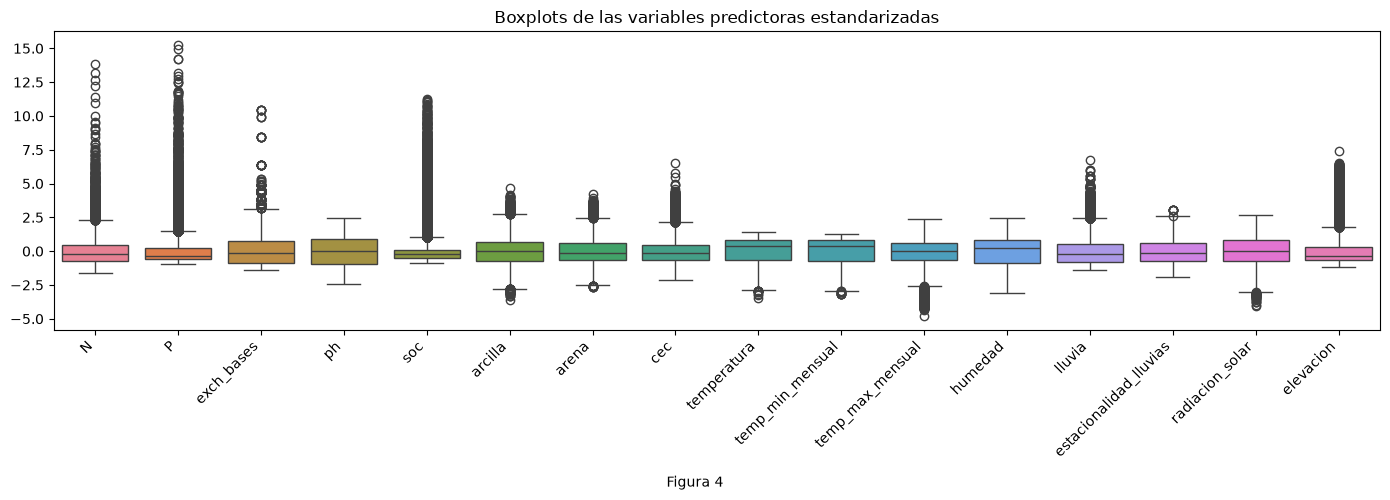

In [14]:
# Grafico los boxplots de las variables estandarizadas para ver los atípicos que conservamos
plt.figure(figsize=(14, 5))
sns.boxplot(data=X_std)
plt.xticks(rotation=45, ha="right")
plt.title("Boxplots de las variables predictoras estandarizadas")
numerar(4)
plt.show()


Figura 4. Los atípicos que conservamos llegan a 15.3 desvíos en P, 13.8 en N y 11.3 en soc. Las variables de temperatura y radiacion_solar solo tienen atípicos por debajo. ph y humedad no tienen puntos fuera de las barras, ya sin las dos filas imposibles. Coincide con la hipótesis: las colas largas de P y soc siguen en los datos.

## 2. SVM con kernel lineal

Exploramos C en 0.01, 0.1, 1, 10 y 100 con SVC(kernel="linear"). Cada valor se evalúa con validación cruzada estratificada de 5 folds sobre las 49803 filas limpias. Reportamos media y desvío de Precision weighted, Recall weighted y Accuracy. Elegimos la configuración más rápida entre las que quedan a un desvío de la mejor Accuracy media.

Hipótesis: los picos múltiples de la Figura 1 indican que los cultivos se solapan en las variables, así que un hiperplano no los separa bien. Esperamos una Accuracy moderada y poca sensibilidad a C, porque la limitación está en el kernel y no en la regularización.

### 2.1 Validación cruzada y criterio de elección

In [15]:
# Defino la validación cruzada estratificada de 5 folds y las tres métricas
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"precision": "precision_weighted", "recall": "recall_weighted", "accuracy": "accuracy"}


# Defino una función que elige la configuración más rápida entre las que quedan a un desvío de la mejor Accuracy media
def mas_rapida(cv_results):
    res = pd.DataFrame(cv_results)
    mejor = res["mean_test_accuracy"].idxmax()
    umbral = res.loc[mejor, "mean_test_accuracy"] - res.loc[mejor, "std_test_accuracy"]
    return res.loc[res["mean_test_accuracy"] >= umbral, "mean_fit_time"].idxmin()


Usamos la misma validación cruzada en las Actividades 2, 3 y 4, así las tres comparaciones usan los mismos folds. Es estratificada, como pide el enunciado, y mezcla las filas antes de armar los folds, porque el CSV está ordenado por clase. En cada fold calculamos las tres métricas que pide el enunciado. En la práctica de la U5, GridSearchCV usa solo la Accuracy.

En cada grilla elegimos la configuración más rápida entre las que quedan a un desvío de la mejor Accuracy media. Este criterio no figura en los apuntes. Las diferencias dentro de un desvío no se distinguen de la variación entre folds, y el tiempo es uno de los criterios de la Actividad 5. El tiempo es el de entrenamiento medio por fold. Los folds corren en paralelo, así que sirve para comparar configuraciones entre sí.

### 2.2 Búsqueda de C

In [16]:
# Busco C con GridSearchCV sobre todo el conjunto limpio; el StandardScaler va dentro del pipeline
grid_lineal = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel="linear", random_state=SEED)),
                           {"svc__C": [0.01, 0.1, 1, 10, 100]},
                           cv=skf, scoring=scoring, refit=mas_rapida, n_jobs=-1)
grid_lineal.fit(X, y)

# Armo la tabla con la media y el desvío de cada métrica en los 5 folds
res = pd.DataFrame(grid_lineal.cv_results_)
res_lineal = pd.DataFrame({"C": res["param_svc__C"]})
for m in scoring:
    res_lineal[m + " media"] = res["mean_test_" + m]
    res_lineal[m + " std"] = res["std_test_" + m]
res_lineal["tiempo de fit (s)"] = res["mean_fit_time"]
display(res_lineal.round(3))
print("Configuración elegida:", grid_lineal.best_params_)


,C,precision media,precision std,recall media,recall std,accuracy media,accuracy std,tiempo de fit (s)
0,0.01,0.605,0.004,0.605,0.004,0.605,0.004,44.795
1,0.10,0.617,0.006,0.618,0.005,0.618,0.005,50.425
2,1.00,0.622,0.005,0.622,0.005,0.622,0.005,94.579
3,10.00,0.623,0.005,0.623,0.005,0.623,0.005,161.216
4,100.00,0.623,0.005,0.623,0.005,0.623,0.005,548.980


Configuración elegida: {'svc__C': 1}


La Accuracy media sube de 0.605 con C=0.01 a 0.622 con C=1, y llega a 0.623 con C=10 y con C=100. Precision y Recall weighted quedan casi iguales a la Accuracy.

La mejor media es la de C=100 (0.623 ± 0.005). C=1 y C=10 quedan dentro de ese desvío, y C=0.1 queda fuera por menos de una milésima. Elegimos C=1, que entrena en 95 s por fold contra 161 s con C=10 y 549 s con C=100.

### 2.3 Métricas según C

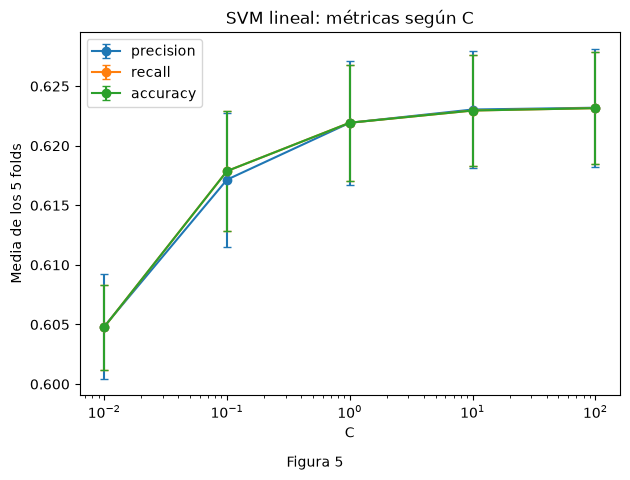

In [17]:
# Grafico las tres métricas medias con su desvío en función de C
for m in scoring:
    plt.errorbar(res_lineal["C"], res_lineal[f"{m} media"], yerr=res_lineal[f"{m} std"],
                 marker="o", capsize=3, label=m)
plt.xscale("log")
plt.xlabel("C")
plt.ylabel("Media de los 5 folds")
plt.title("SVM lineal: métricas según C")
plt.legend()
numerar(5)
plt.show()


Figura 5. La Accuracy se aplana desde C=1: de 1 a 100 gana solo 0.001. Las tres métricas se superponen y las barras de error cubren las diferencias entre C=1, 10 y 100. La hipótesis se cumple: la Accuracy ronda 0.62 y C cambia poco el resultado, así que el límite lo pone la frontera lineal.

## 3. SVM con kernel gaussiano (RBF)

Probamos C en 0.1, 1, 10 y 100, y gamma en 0.001, 0.01, 0.1 y 1 (16 combinaciones y 80 entrenamientos), con el mismo StratifiedKFold y el mismo pipeline.

Hipótesis: el RBF mejora mucho al lineal, porque el solapamiento entre cultivos no es lineal. Con gamma chico esperamos subajuste, y la mejor zona con C y gamma medios o altos.

### 3.1 Búsqueda de C y gamma

In [18]:
# Busco C y gamma con GridSearchCV (16 combinaciones) sobre todo el conjunto limpio
param_rbf = {"svc__C": [0.1, 1, 10, 100], "svc__gamma": [0.001, 0.01, 0.1, 1]}
grid_rbf = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel="rbf", random_state=SEED)),
                        param_rbf, cv=skf, scoring=scoring, refit=mas_rapida, n_jobs=-1)
grid_rbf.fit(X, y)

# Armo la tabla con la media y el desvío de cada métrica en los 5 folds
res = pd.DataFrame(grid_rbf.cv_results_)
res_rbf = pd.DataFrame({"C": res["param_svc__C"], "gamma": res["param_svc__gamma"]})
for m in scoring:
    res_rbf[m + " media"] = res["mean_test_" + m]
    res_rbf[m + " std"] = res["std_test_" + m]
res_rbf["tiempo de fit (s)"] = res["mean_fit_time"]
display(res_rbf.sort_values("accuracy media", ascending=False).round(3))
print("Configuración elegida:", grid_rbf.best_params_)


,C,gamma,precision media,precision std,recall media,recall std,accuracy media,accuracy std,tiempo de fit (s)
11,10.0,1.000,0.888,0.003,0.886,0.003,0.886,0.003,89.239
14,100.0,0.100,0.884,0.002,0.885,0.002,0.885,0.002,32.845
7,1.0,1.000,0.883,0.003,0.881,0.003,0.881,0.003,86.648
15,100.0,1.000,0.883,0.002,0.881,0.003,0.881,0.003,52.323
10,10.0,0.100,0.868,0.004,0.869,0.004,0.869,0.004,24.700
6,1.0,0.100,0.824,0.003,0.824,0.003,0.824,0.003,26.270
13,100.0,0.010,0.805,0.004,0.806,0.004,0.806,0.004,43.704
3,0.1,1.000,0.827,0.006,0.761,0.006,0.761,0.006,100.483
9,10.0,0.010,0.752,0.006,0.751,0.006,0.751,0.006,34.228
2,0.1,0.100,0.742,0.004,0.741,0.005,0.741,0.005,42.161


Configuración elegida: {'svc__C': 100, 'svc__gamma': 0.1}


La mejor media es la de C=10 y gamma=1 (0.886). Dentro de su desvío queda también C=100 con gamma=0.1 (0.885), y C=1 con gamma=1 (0.881) queda fuera. Elegimos C=100 y gamma=0.1: entrena en 33 s por fold contra 89 s y tiene el menor desvío de la tabla (0.002).

Precision y Recall weighted acompañan a la Accuracy, salvo con C=0.1 y gamma=1: ahí la Precision llega a 0.827 y la Accuracy a 0.761.

C=100 está en el borde de la grilla. Valores mayores podrían rendir algo más.

### 3.2 Interacción entre C y gamma

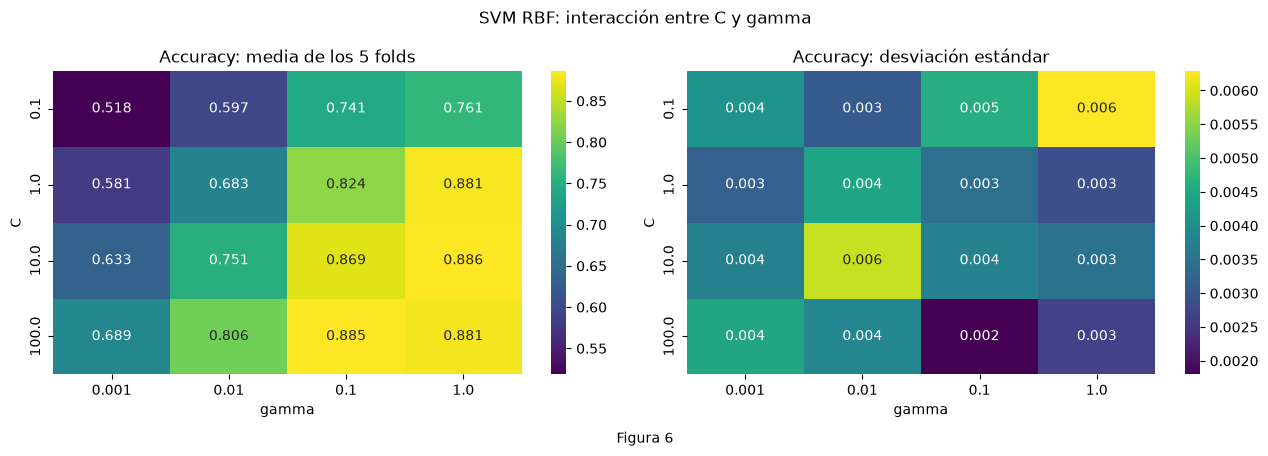

In [19]:
# Grafico la media y el desvío de la Accuracy según C y gamma
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (col, titulo) in zip(axes, [("accuracy media", "Accuracy: media de los 5 folds"),
                                    ("accuracy std", "Accuracy: desviación estándar")]):
    sns.heatmap(res_rbf.pivot(index="C", columns="gamma", values=col), annot=True, fmt=".3f", cmap="viridis", ax=ax)
    ax.set_title(titulo)
plt.suptitle("SVM RBF: interacción entre C y gamma")
numerar(6)
plt.show()


Figura 6. Con gamma=0.001 la Accuracy no pasa de 0.689 aunque C llegue a 100: esa columna subajusta, como esperábamos. Los valores altos, entre 0.824 y 0.886, se concentran con C de 1 en adelante y gamma de 0.1 en adelante. Con gamma=1, la Accuracy baja levemente al pasar de C=10 a C=100. El desvío va de 0.002 a 0.006.

El RBF elegido (0.885) supera al lineal elegido (0.622) por 0.263, y la hipótesis se cumple.

## 4. Random Forest

Probamos n_estimators en 50, 100, 200 y 500, y max_depth en 5, 10, 20 y None (16 combinaciones y 80 entrenamientos), con el mismo StratifiedKFold. El Random Forest se entrena con X sin estandarizar.

Hipótesis: el Random Forest supera al RBF, porque cortes por umbral sobre las variables climáticas separan bien los cultivos. max_depth pesa más que n_estimators. Las variables de clima y ubicación (temperaturas, lluvia, humedad, radiación, elevación) lideran la importancia, por encima de las de suelo.

### 4.1 Búsqueda de n_estimators y max_depth

In [20]:
# Busco n_estimators y max_depth con GridSearchCV (16 combinaciones); Random Forest se entrena sin estandarizar
param_rf = {"n_estimators": [50, 100, 200, 500], "max_depth": [5, 10, 20, None]}
grid_rf = GridSearchCV(RandomForestClassifier(random_state=SEED), param_rf,
                       cv=skf, scoring=scoring, refit=mas_rapida, n_jobs=-1)
grid_rf.fit(X, y)

# Armo la tabla con la media y el desvío de cada métrica en los 5 folds
res = pd.DataFrame(grid_rf.cv_results_)
res_rf = pd.DataFrame({"max_depth": res["param_max_depth"], "n_estimators": res["param_n_estimators"]})
for m in scoring:
    res_rf[m + " media"] = res["mean_test_" + m]
    res_rf[m + " std"] = res["std_test_" + m]
res_rf["tiempo de fit (s)"] = res["mean_fit_time"]
display(res_rf.sort_values("accuracy media", ascending=False).round(3))
print("Configuración elegida:", grid_rf.best_params_)


,max_depth,n_estimators,precision media,precision std,recall media,recall std,accuracy media,accuracy std,tiempo de fit (s)
15,None,500,0.916,0.004,0.917,0.004,0.917,0.004,68.627
14,None,200,0.915,0.004,0.915,0.004,0.915,0.004,33.296
13,None,100,0.914,0.003,0.915,0.003,0.915,0.003,16.519
11,20,500,0.914,0.004,0.914,0.004,0.914,0.004,79.107
10,20,200,0.913,0.003,0.914,0.004,0.914,0.004,31.982
12,None,50,0.913,0.004,0.914,0.004,0.914,0.004,8.470
9,20,100,0.912,0.003,0.912,0.003,0.912,0.003,16.765
8,20,50,0.910,0.003,0.911,0.003,0.911,0.003,8.052
7,10,500,0.846,0.004,0.843,0.005,0.843,0.005,55.986
6,10,200,0.845,0.005,0.842,0.005,0.842,0.005,22.098


Configuración elegida: {'max_depth': None, 'n_estimators': 50}


La mejor media es la de max_depth=None y 500 árboles (0.917). Seis configuraciones quedan dentro de su desvío, todas con max_depth de 20 o None. Elegimos max_depth=None y 50 árboles: llega a 0.914 y entrena en 8 s por fold, contra 69 s de la de 500.

max_depth pesa mucho: la Accuracy ronda 0.64 con max_depth=5, 0.84 con 10 y 0.91 con 20 o None. n_estimators pesa poco: con max_depth=None, pasar de 50 a 500 árboles sube la Accuracy solo 0.003, menos que el desvío.

Con max_depth=5, la Precision queda unos dos puntos por encima de la Accuracy (de 0.659 a 0.664, contra 0.639 a 0.646). Con más profundidad, las dos quedan a 0.004 o menos.

### 4.2 Interacción entre n_estimators y max_depth

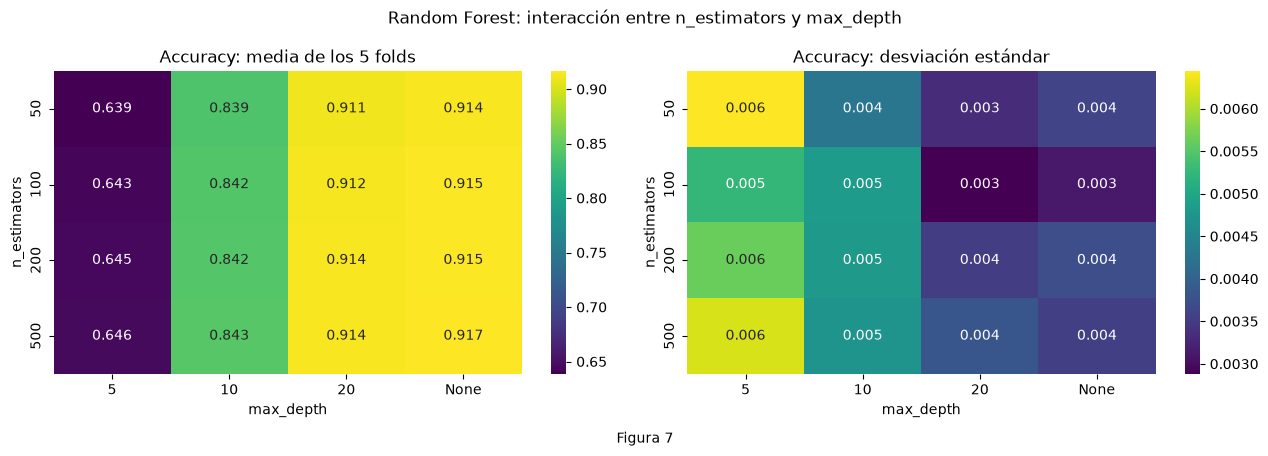

In [21]:
# Grafico la media y el desvío de la Accuracy según n_estimators y max_depth
res_rf["max_depth"] = res_rf["max_depth"].map(str)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (col, titulo) in zip(axes, [("accuracy media", "Accuracy: media de los 5 folds"),
                                    ("accuracy std", "Accuracy: desviación estándar")]):
    sns.heatmap(res_rf.pivot(index="n_estimators", columns="max_depth", values=col)[["5", "10", "20", "None"]],
                annot=True, fmt=".3f", cmap="viridis", ax=ax)
    ax.set_title(titulo)
plt.suptitle("Random Forest: interacción entre n_estimators y max_depth")
numerar(7)
plt.show()


Figura 7. La Accuracy cambia sobre todo con max_depth: sube cerca de 0.20 de 5 a 10 y cerca de 0.07 de 10 a 20, y casi no cambia entre 20 y None. Con max_depth de 10 en adelante, n_estimators mueve la Accuracy 0.004 o menos. El desvío es más alto con max_depth=5. La hipótesis sobre max_depth y n_estimators se cumple.

### 4.3 Importancia de las variables

,features,importances
9,temp_min_mensual,0.110
8,temperatura,0.090
12,lluvia,0.090
14,radiacion_solar,0.089
10,temp_max_mensual,0.088
11,humedad,0.088
13,estacionalidad_lluvias,0.074
15,elevacion,0.072
3,ph,0.041
7,cec,0.041


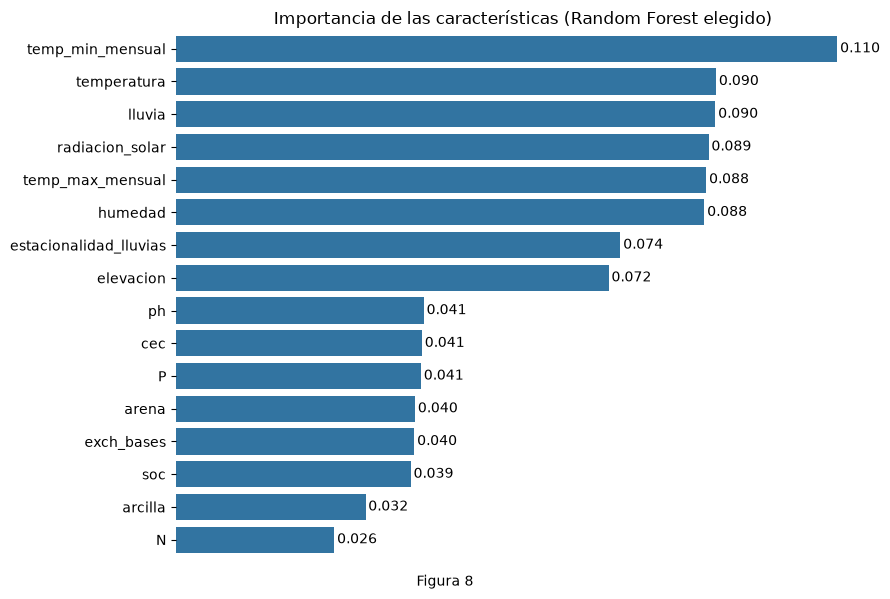

In [22]:
# Armo una tabla con la importancia de cada variable en el Random Forest elegido y la grafico
importancias = pd.DataFrame({"features": X.columns, "importances": grid_rf.best_estimator_.feature_importances_})
importancias = importancias.sort_values(by="importances", ascending=False)
display(importancias.round(3))

plt.figure(figsize=(9, 6))
g = sns.barplot(data=importancias, x="importances", y="features")
sns.despine(bottom=True, left=True)
g.set_title("Importancia de las características (Random Forest elegido)")
g.set(xlabel=None, ylabel=None, xticks=[])
for value in g.containers:
    g.bar_label(value, padding=2, fmt="%.3f")
numerar(8)
plt.show()


Figura 8. En el Random Forest elegido, reentrenado con todos los datos, las ocho variables más importantes son de clima o ubicación y suman 0.70. temp_min_mensual encabeza con 0.110. Ninguna variable de suelo supera 0.041 (ph), y la menor es N (0.026). La hipótesis se cumple. temperatura y temp_min_mensual tienen correlación de 0.95 (Figura 3), así que la importancia se reparte entre ellas.

## 5. Comparación de modelos

La tabla reúne la configuración elegida de cada algoritmo en las Actividades 2 a 4, con media y desvío de los 5 folds y el tiempo medio de entrenamiento por fold. Para las matrices de confusión usamos el primer fold de la validación cruzada: entrenamos cada configuración elegida con los otros 4 folds y predecimos ese fold.

Hipótesis: la Accuracy en el primer fold queda cerca de la media de validación cruzada, y el lineal confunde más clases que los otros dos.

### 5.1 Tabla comparativa

In [23]:
# Armo la tabla comparativa con la configuración elegida de cada algoritmo
grids = {"SVM lineal": grid_lineal, "SVM RBF": grid_rbf, "Random Forest": grid_rf}
filas = []
for nombre, g in grids.items():
    res = pd.DataFrame(g.cv_results_)
    i = g.best_index_
    fila = {"algoritmo": nombre, "configuración": g.best_params_}
    for m in scoring:
        fila[m + " media"] = res.loc[i, "mean_test_" + m]
        fila[m + " std"] = res.loc[i, "std_test_" + m]
    fila["tiempo de fit (s)"] = res.loc[i, "mean_fit_time"]
    filas.append(fila)
display(pd.DataFrame(filas).round(3))


,algoritmo,configuración,precision media,precision std,recall media,recall std,accuracy media,accuracy std,tiempo de fit (s)
0,SVM lineal,{'svc__C': 1},0.622,0.005,0.622,0.005,0.622,0.005,94.579
1,SVM RBF,"{'svc__C': 100, 'svc__gamma': 0.1}",0.884,0.002,0.885,0.002,0.885,0.002,32.845
2,Random Forest,"{'max_depth': None, 'n_estimators': 50}",0.913,0.004,0.914,0.004,0.914,0.004,8.470


La Accuracy media es 0.622 en el SVM lineal, 0.885 en el RBF y 0.914 en el Random Forest. Precision y Recall weighted acompañan a la Accuracy en los tres. El Random Forest supera al RBF por 0.029, más de siete veces su desvío (0.004). La hipótesis de la Actividad 4 se cumple: el Random Forest supera al RBF. El RBF es el más estable entre folds (desvío de 0.002), seguido por el Random Forest (0.004) y el lineal (0.005).

### 5.2 Matrices de confusión

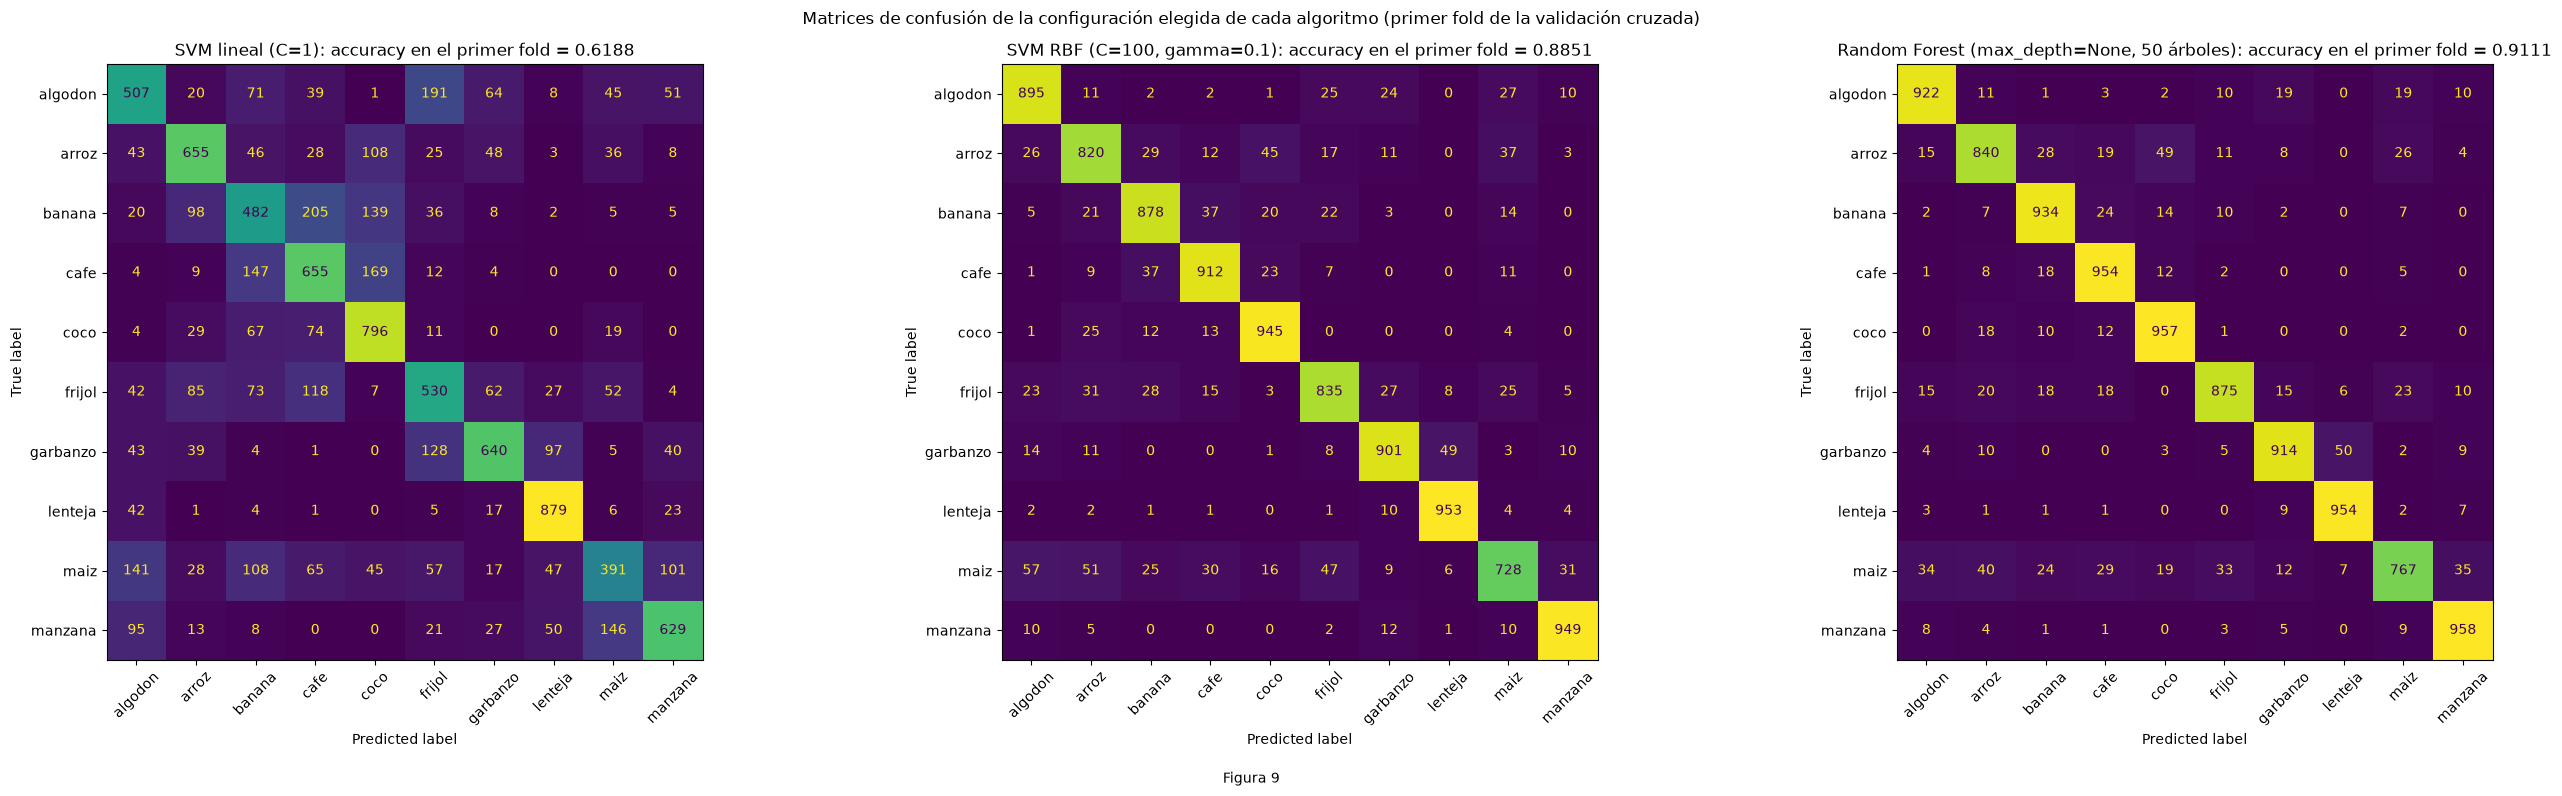

In [24]:
# Armo la configuración elegida de cada algoritmo, la entreno con 4 folds, predigo el primer fold y grafico sus matrices de confusión
entrena, prueba = next(skf.split(X, y))
modelos = {
    "SVM lineal (C=1)": make_pipeline(StandardScaler(), SVC(kernel="linear", C=1, random_state=SEED)),
    "SVM RBF (C=100, gamma=0.1)": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=100, gamma=0.1, random_state=SEED)),
    "Random Forest (max_depth=None, 50 árboles)": RandomForestClassifier(n_estimators=50, max_depth=None, random_state=SEED),
}
fig, axes = plt.subplots(1, 3, figsize=(27, 8))
for ax, (nombre, modelo) in zip(axes, modelos.items()):
    pred = modelo.fit(X.iloc[entrena], y[entrena]).predict(X.iloc[prueba])
    cm = confusion_matrix(y[prueba], pred)
    ConfusionMatrixDisplay(cm, display_labels=le.classes_).plot(ax=ax, colorbar=False, xticks_rotation=45)
    ax.set_title(f"{nombre}: accuracy en el primer fold = {accuracy_score(y[prueba], pred):.4f}")
plt.suptitle("Matrices de confusión de la configuración elegida de cada algoritmo (primer fold de la validación cruzada)")
numerar(9)
plt.show()


Figura 9. En el primer fold la Accuracy es 0.619 (lineal), 0.885 (RBF) y 0.911 (Random Forest), dentro de un desvío de su media de validación cruzada. El lineal confunde más clases: su mayor error es banana predicha como cafe (205 veces), y su Recall por clase va de 0.391 (maiz) a 0.899 (lenteja). Las dos partes de la hipótesis se cumplen.

El RBF y el Random Forest tienen la diagonal mucho más marcada. maiz es la clase más difícil en los tres modelos, con Recall de 0.391, 0.728 y 0.767. garbanzo se confunde con lenteja en los dos (49 y 50 veces). El Random Forest acierta más que el RBF en las diez clases.

### 5.3 Modelo elegido

Elegimos el Random Forest:

- Tiene las mejores métricas: Accuracy de 0.914 en validación cruzada, contra 0.885 del RBF y 0.622 del lineal.
- Su desvío (0.004) duplica el del RBF (0.002), pero es chico frente a la diferencia de 0.029 entre ambos.
- Entrena en 8 s por fold, contra 33 s del RBF y 95 s del lineal.
- Entrega la importancia de las variables (Figura 8). Las diapositivas de la U6 cuentan esa estimación entre las ventajas del Random Forest, y las de la U5 señalan que un SVM con kernel no lineal es difícil de interpretar.

El lineal queda descartado por su Accuracy. El RBF es la segunda opción y el más estable entre folds.

## 6. Conclusiones

Eliminamos 201 de 50004 filas: 198 duplicadas, una con tres nulos y dos con valores imposibles (por ejemplo, un ph de 25.3). Conservamos los atípicos por IQR, porque son colas largas posibles. El conjunto limpio tiene 49803 filas y un desbalance leve (razón de 1.022), que aparece recién al eliminar duplicados.

Con validación cruzada estratificada de 5 folds, la Accuracy media fue 0.622 en el SVM lineal (C=1), 0.885 en el RBF (C=100, gamma=0.1) y 0.914 en el Random Forest (max_depth=None, 50 árboles). En cada algoritmo elegimos la configuración más rápida dentro de un desvío de la mejor media. Elegimos el Random Forest: supera al RBF por 0.029, más de siete veces su desvío, entrena en 8 s por fold contra 33 s y 95 s, y da la importancia de las variables. Las 8 de clima y ubicación suman 0.70 de esa importancia.

Casi todas las hipótesis se cumplieron: colas a la derecha, poca mejora del lineal con C, RBF por encima del lineal, subajuste del RBF con gamma chico, Random Forest por encima del RBF, max_depth por encima de n_estimators y clima por encima de suelo. La de temperaturas se cumplió en parte: temp_min_mensual y temp_max_mensual solo llegan a 0.52 entre sí. La del desbalance no se cumplió en el archivo original: aparece al eliminar duplicados. En el primer fold, maiz fue la clase más difícil en los tres modelos.

Limitaciones: el RBF elegido queda en el borde de la grilla (C=100), la Figura 9 usa un solo fold, los tiempos se midieron con los folds en paralelo y usamos una sola semilla (13).